# Climate-Aware Solar Material Screening via Graph Neural Networks

Team: Isaac Humphries, Vamsi Marrapu, Abdul Mutaal | CSC 4444

**Pipeline overview**
1. Ingest materials data (Materials Project API, band gap 0.5–3.5 eV)
2. Baseline ML - Random Forest & Gradient Boosting on composition/structural features
3. Graph construction - crystal structures to PyG Data objects
4. GNN training - GCN, GAT, GIN with Physics-Informed Loss
5. Model comparison - GNN vs baselines, learning curves
6. GNNExplainer - visualise which atoms/bonds drove each prediction
7. Climate fusion - NASA POWER irradiance into solar yield proxy per US location
8. Final ranking against silicon baseline

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split

from src.data_utils import (
    fetch_materials, extract_baseline_features,
    build_graph_dataset, split_dataset,
    cache_data, load_cached_data,
)
from src.models import GCN, GAT, GIN, PhysicsInformedLoss, train_model, evaluate
from src.baselines import train_and_evaluate, get_feature_importance

# Config
SUBSET_MODE     = False   # False = full database (~50k materials)
MAX_SAMPLES     = 2000    # only used when SUBSET_MODE=True
BATCH_SIZE      = 32
EPOCHS          = 80
LR              = 1e-3
DEVICE          = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_WANDB       = False
CACHE_PATH      = 'data/materials_cache.pkl'
SEED            = 42

# Pretrained Models
PRETRAINED_MODE = True
MODELS_DIR      = 'models'
BASELINE_DIR    = 'models/baselines'

CITY      = 'Baton Rouge, LA'
CITY_LAT  = 30.45
CITY_LON  = -91.15

np.random.seed(SEED)
torch.manual_seed(SEED)
print(f'Device: {DEVICE} - PyTorch {torch.__version__}')
print(f'Target city: {CITY}')
print(f'Pretrained mode: {PRETRAINED_MODE}')
print(f'Full database fetch: {not SUBSET_MODE}  (note: full fetch may take 10–20 min)')

Device: cuda - PyTorch 2.11.0+cu128
Target city: Baton Rouge, LA
Pretrained mode: True
Full database fetch: True  (note: full fetch may take 10–20 min)


## Step 1 - Data Ingestion

In [2]:
MIN_FULL_SIZE = 50_000   # cache must have at least this many rows to be used in full mode

_cached = load_cached_data(CACHE_PATH)

if _cached is not None:
    n_cached = len(_cached)
    print(f'Cache found: {n_cached} rows')
    if SUBSET_MODE:
        if n_cached < MAX_SAMPLES:
            print(f'  Cache ({n_cached}) < MAX_SAMPLES ({MAX_SAMPLES}) — fetching fresh subset.')
            _cached = None
        else:
            _cached = _cached.sample(n=MAX_SAMPLES, random_state=SEED).reset_index(drop=True)
            print(f'  Sampled {MAX_SAMPLES} rows from cache.')
    else:
        if n_cached < MIN_FULL_SIZE:
            print(f'  Cache ({n_cached}) < MIN_FULL_SIZE ({MIN_FULL_SIZE}) — fetching full database.')
            _cached = None
        else:
            print(f'  Using full cache ({n_cached} rows).')

if _cached is None:
    print('Fetching from Materials Project API …')
    df = fetch_materials(subset_mode=SUBSET_MODE, max_samples=MAX_SAMPLES)
    cache_data(df, CACHE_PATH)
    print(f'Fetched and cached {len(df)} materials.')
else:
    df = _cached

df = df.dropna(subset=['band_gap', 'formation_energy_per_atom']).reset_index(drop=True)
print(f'Clean dataset: {df.shape}')
df[['formula','band_gap','formation_energy_per_atom','density','nsites','nelements']].head(10)

INFO | Loaded 51162 rows from cache (data/materials_cache.pkl)


Cache found: 51162 rows
  Using full cache (51162 rows).
Clean dataset: (51162, 10)


,formula,band_gap,formation_energy_per_atom,density,nsites,nelements
0,Ac2S3,2.2962,-2.493064,6.535149,40,2
1,Ac2S3,3.0275,-2.440364,5.562971,10,2
2,AcBO3,0.8071,-2.475390,9.206879,5,3
3,AcCrO3,2.0031,-3.138972,8.848788,5,3
4,AcFeO3,0.9888,-2.771539,8.889999,5,3
5,AcGaO3,2.8959,-3.063253,9.314495,5,3
6,AcH3,0.6407,-0.671802,7.784734,4,2
7,AcI3,2.5892,-1.801003,4.334420,8,2
8,AcScO3,3.3847,-3.829060,7.569207,5,3
9,AcTlTe2,0.6253,-1.251403,8.430613,4,3


## Step 1b: Exploratory Data Analysis

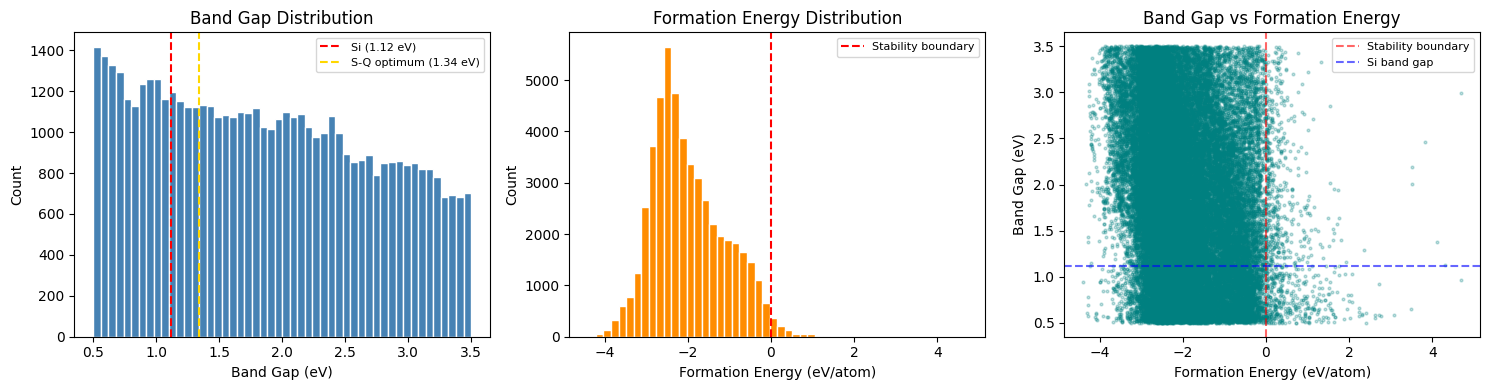

Stable materials (FE < 0): 50254/51162 (98.2%)
        band_gap  formation_energy_per_atom
count  51162.000                  51162.000
mean       1.852                     -1.983
std        0.850                      0.891
min        0.500                     -4.389
25%        1.109                     -2.620
50%        1.796                     -2.156
75%        2.543                     -1.410
max        3.500                      4.688


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df['band_gap'], bins=50, color='steelblue', edgecolor='white')
axes[0].axvline(1.12, color='red', linestyle='--', label='Si (1.12 eV)')
axes[0].axvline(1.34, color='gold', linestyle='--', label='S-Q optimum (1.34 eV)')
axes[0].set(xlabel='Band Gap (eV)', ylabel='Count', title='Band Gap Distribution')
axes[0].legend(fontsize=8)

axes[1].hist(df['formation_energy_per_atom'], bins=50, color='darkorange', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', label='Stability boundary')
axes[1].set(xlabel='Formation Energy (eV/atom)', ylabel='Count', title='Formation Energy Distribution')
axes[1].legend(fontsize=8)

axes[2].scatter(df['formation_energy_per_atom'], df['band_gap'], alpha=0.25, s=4, c='teal')
axes[2].axvline(0, color='red', linestyle='--', alpha=0.6, label='Stability boundary')
axes[2].axhline(1.12, color='blue', linestyle='--', alpha=0.6, label='Si band gap')
axes[2].set(xlabel='Formation Energy (eV/atom)', ylabel='Band Gap (eV)', title='Band Gap vs Formation Energy')
axes[2].legend(fontsize=8)

plt.tight_layout()
os.makedirs('data', exist_ok=True)
plt.savefig('data/eda_distributions.png', dpi=120, bbox_inches='tight')
plt.show()

stable = (df['formation_energy_per_atom'] < 0).sum()
print(f'Stable materials (FE < 0): {stable}/{len(df)} ({100*stable/len(df):.1f}%)')
print(df[['band_gap','formation_energy_per_atom']].describe().round(3))

## Step 2: Baseline Models (Random Forest & Gradient Boosting)

In [4]:
print('Extracting composition / structural features ...')
X, y_bg, y_fe = extract_baseline_features(df)
print(f'Feature matrix: {X.shape}')

X_tr, X_te, y_bg_tr, y_bg_te, y_fe_tr, y_fe_te = train_test_split(
    X, y_bg, y_fe, test_size=0.2, random_state=SEED
)
print(f'Train: {X_tr.shape[0]} - Test: {X_te.shape[0]}')

Extracting composition / structural features ...
Feature matrix: (51162, 22)
Train: 40929 - Test: 10233


In [5]:
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

_BASELINE_FILES = {
    'rf_bandgap':   'rf_bandgap_pipeline.joblib',
    'rf_formation': 'rf_formation_pipeline.joblib',
    'gb_bandgap':   'gb_bandgap_pipeline.joblib',
    'gb_formation': 'gb_formation_pipeline.joblib',
}
_all_baselines_exist = all(
    os.path.exists(os.path.join(BASELINE_DIR, f)) for f in _BASELINE_FILES.values()
)

if PRETRAINED_MODE and _all_baselines_exist:
    print('Loading pretrained baseline models from models/baselines directory ...')
    fitted_pipelines = {
        key: joblib.load(os.path.join(BASELINE_DIR, fname))
        for key, fname in _BASELINE_FILES.items()
    }
    _task_map = {
        'rf_bandgap':   (y_bg_te, 'band_gap',        'Random Forest'),
        'rf_formation': (y_fe_te, 'formation_energy', 'Random Forest'),
        'gb_bandgap':   (y_bg_te, 'band_gap',        'Gradient Boosting'),
        'gb_formation': (y_fe_te, 'formation_energy', 'Gradient Boosting'),
    }
    records = []
    for key, (y_te_i, target, model_label) in _task_map.items():
        y_pred = fitted_pipelines[key].predict(X_te)
        records.append({
            'model':     model_label,
            'target':    target,
            'cv_mae':    '(pretrained)',
            'test_mae':  round(mean_absolute_error(y_te_i, y_pred), 4),
            'test_rmse': round(np.sqrt(mean_squared_error(y_te_i, y_pred)), 4),
            'test_r2':   round(r2_score(y_te_i, y_pred), 4),
        })
    baseline_metrics = pd.DataFrame(records)
    print('Evaluated pretrained models on current test split')
else:
    print('Training baseline models ...')
    baseline_metrics, fitted_pipelines = train_and_evaluate(
        X_tr, X_te, y_bg_tr, y_bg_te, y_fe_tr, y_fe_te
    )

print('\nBaseline Performance:')
baseline_metrics

Loading pretrained baseline models from models/baselines directory ...
Evaluated pretrained models on current test split

Baseline Performance:


,model,target,cv_mae,test_mae,test_rmse,test_r2
0,Random Forest,band_gap,(pretrained),0.4415,0.5840,0.5325
1,Random Forest,formation_energy,(pretrained),0.1208,0.2136,0.9430
2,Gradient Boosting,band_gap,(pretrained),0.5550,0.6815,0.3634
3,Gradient Boosting,formation_energy,(pretrained),0.1979,0.2789,0.9029


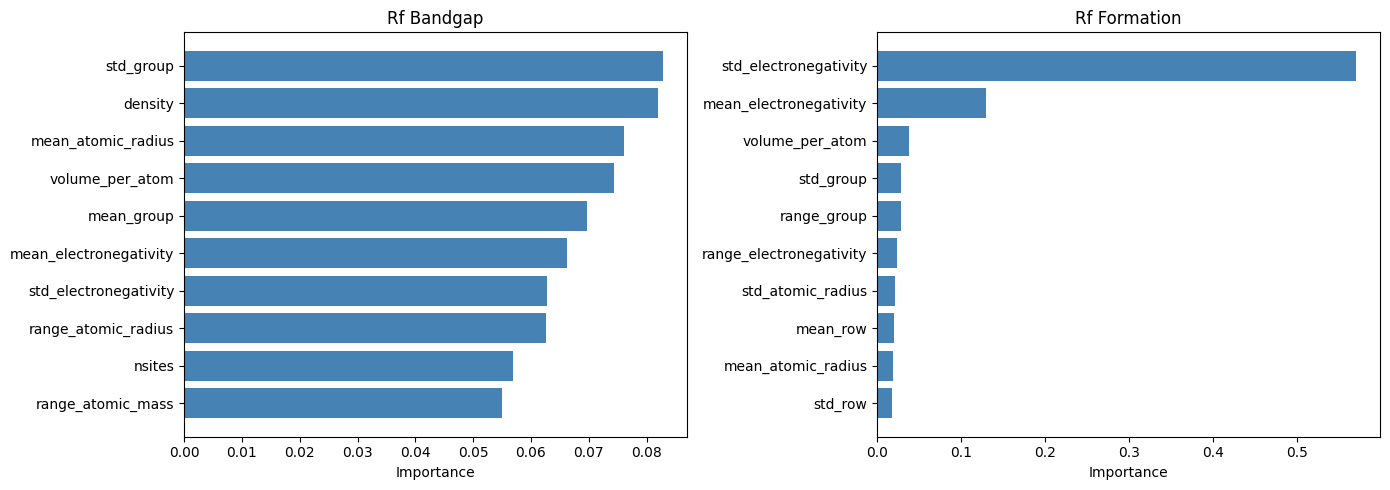

In [6]:
importance_dfs = get_feature_importance(fitted_pipelines, top_n=10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, imp_df) in zip(axes, importance_dfs.items()):
    ax.barh(imp_df['feature'], imp_df['importance'], color='steelblue')
    ax.invert_yaxis()
    ax.set(xlabel='Importance', title=name.replace('_',' ').title())
plt.tight_layout()
plt.savefig('data/feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 3: Graph Dataset Construction

In [7]:
_GRAPH_FILES = {
    'train': 'data/train_graphs.pt',
    'val':   'data/val_graphs.pt',
    'test':  'data/test_graphs.pt',
}
_graphs_exist = all(os.path.exists(p) for p in _GRAPH_FILES.values())

if PRETRAINED_MODE and _graphs_exist:
    print('Loading pre-built graph splits from data directory ...')
    train_g = torch.load(_GRAPH_FILES['train'], map_location='cpu', weights_only=False)
    val_g   = torch.load(_GRAPH_FILES['val'],   map_location='cpu', weights_only=False)
    test_g  = torch.load(_GRAPH_FILES['test'],  map_location='cpu', weights_only=False)
    g0 = train_g[0]
    print(f'Sample ({g0.formula}): {g0.num_nodes} nodes, {g0.num_edges} edges, {g0.num_node_features} node features')
    print(f'Split : Train: {len(train_g)}  Val: {len(val_g)}  Test: {len(test_g)}')
else:
    print('Converting crystal structures to molecular graphs (cutoff = 5.0)')
    graphs = build_graph_dataset(df, cutoff=5.0)
    print(f'\nGraph dataset: {len(graphs)} graphs')
    g0 = graphs[0]
    print(f'Sample ({g0.formula}): {g0.num_nodes} nodes, {g0.num_edges} edges, {g0.num_node_features} node features')
    train_g, val_g, test_g = split_dataset(graphs, train_ratio=0.70, val_ratio=0.15, seed=SEED)
    print(f'Split : Train: {len(train_g)}  Val: {len(val_g)}  Test: {len(test_g)}')

train_loader = DataLoader(train_g, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_g,   batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_g,  batch_size=BATCH_SIZE)

Loading pre-built graph splits from data directory ...
Sample (K3GeH2NO3): 20 nodes, 612 edges, 11 node features
Split : Train: 35812  Val: 7674  Test: 7674


## Step 4: GNN Training (GCN - GAT - GIN)

In [8]:
import pickle as _pkl

NODE_FEATURES = train_g[0].num_node_features
gnn_results   = {}

model_specs = [
    ('GCN', GCN, {'hidden_dim': 128, 'num_layers': 3}),
    ('GAT', GAT, {'hidden_dim': 64,  'num_layers': 3, 'heads': 4}),
    ('GIN', GIN, {'hidden_dim': 128, 'num_layers': 3}),
]

_gnn_files_exist = all(
    os.path.exists(f'{MODELS_DIR}/{name}_weights.pt') and
    os.path.exists(f'{MODELS_DIR}/{name}_history.pkl')
    for name, _, _ in model_specs
)

if PRETRAINED_MODE and _gnn_files_exist:
    print('Loading pretrained GNN weights from models directory ...')
    for model_name, ModelClass, kwargs in model_specs:
        model = ModelClass(node_features=NODE_FEATURES, **kwargs).to(DEVICE)
        model.load_state_dict(torch.load(
            f'{MODELS_DIR}/{model_name}_weights.pt',
            map_location=DEVICE, weights_only=False,
        ))
        model.eval()
        with open(f'{MODELS_DIR}/{model_name}_history.pkl', 'rb') as _f:
            history = _pkl.load(_f)
        test_metrics = evaluate(model, test_loader, PhysicsInformedLoss(), DEVICE)
        gnn_results[model_name] = {'model': model, 'history': history, 'test': test_metrics}
        print(f'  {model_name} | MAE band gap: {test_metrics["mae_bandgap"]:.4f} eV | '
              f'MAE formation: {test_metrics["mae_formation"]:.4f} eV/atom')
else:
    if USE_WANDB:
        import wandb
        wandb.login()

    for model_name, ModelClass, kwargs in model_specs:
        print(f'\n{"="*55}')
        print(f'Training {model_name} ...')

        if USE_WANDB:
            wandb.init(project='solar-materials', name=model_name, reinit=True)

        model = ModelClass(node_features=NODE_FEATURES, **kwargs)
        n_params = sum(p.numel() for p in model.parameters())
        print(f'Parameters: {n_params:,}')

        trained, history = train_model(
            model, train_loader, val_loader,
            epochs=EPOCHS, lr=LR, device=DEVICE,
            model_name=model_name, use_wandb=USE_WANDB,
        )

        test_metrics = evaluate(trained, test_loader, PhysicsInformedLoss(), DEVICE)
        gnn_results[model_name] = {'model': trained, 'history': history, 'test': test_metrics}

        print(f'\n{model_name} Test | MAE band gap: {test_metrics["mae_bandgap"]:.4f} eV | '
              f'MAE formation: {test_metrics["mae_formation"]:.4f} eV/atom')

        if USE_WANDB:
            wandb.log(test_metrics)
            wandb.finish()

Loading pretrained GNN weights from models directory ...
  GCN | MAE band gap: 0.5400 eV | MAE formation: 0.1716 eV/atom
  GAT | MAE band gap: 0.4977 eV | MAE formation: 0.1442 eV/atom
  GIN | MAE band gap: 0.5963 eV | MAE formation: 0.2692 eV/atom


## Step 5: Model Comparison

GNN Results (physics-informed loss used during training):
Model  Saved Epoch  MAE Band Gap (eV)  MAE Formation (eV/atom)  Physics Loss (test)
  GCN           71             0.5400                   0.1716              0.57842
  GAT           73             0.4977                   0.1442              0.48870
  GIN           36             0.5963                   0.2692              0.78933

Learning curves (Google Colab training run)


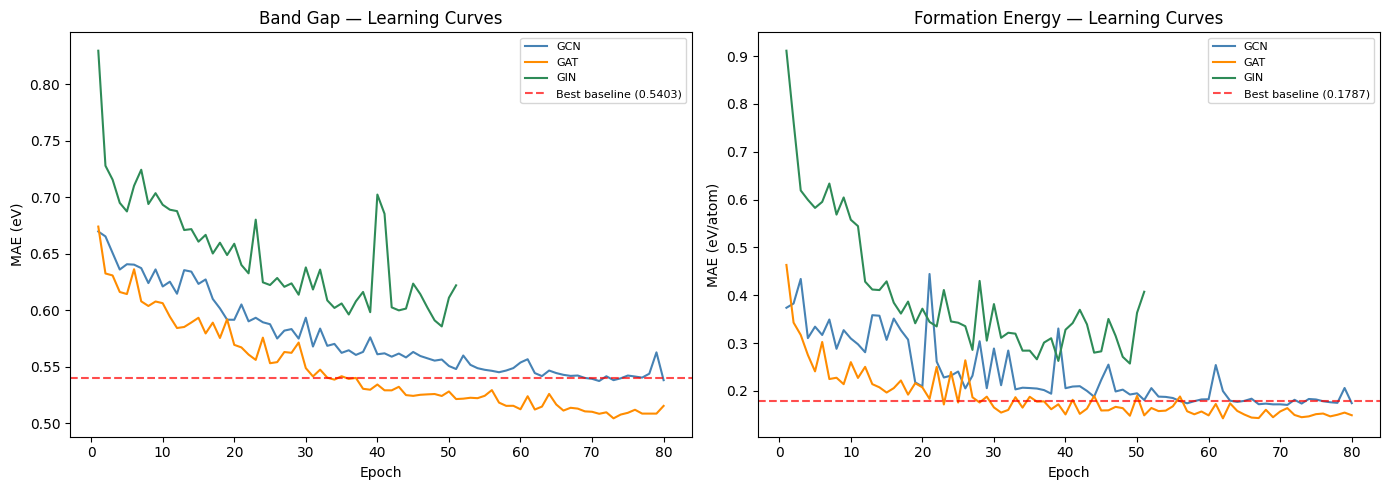


Best baseline MAE - Band Gap: 0.4415 eV | Formation Energy: 0.1208 eV/atom

Physics loss = weighted MSE(band_gap) + weighted MSE(formation_energy) + 5x penalty when predicted FE crosses the FE=0 stability boundary
The penalty fires on sign-flip errors (stable to unstable or vice-versa) the most consequential mistake for solar material screening.


In [9]:
gnn_cmp = pd.DataFrame([
    {
        'Model':                   name,
        'Saved Epoch':             int(r['history'].loc[r['history']['loss'].idxmin(), 'epoch']),
        'MAE Band Gap (eV)':       round(r['test']['mae_bandgap'], 4),
        'MAE Formation (eV/atom)': round(r['test']['mae_formation'], 4),
        'Physics Loss (test)':     round(r['test']['loss'], 5),
    }
    for name, r in gnn_results.items()
])
print('GNN Results (physics-informed loss used during training):')
print(gnn_cmp.to_string(index=False))


# The learning curves below were produced during the full training run on
# Google Colab (T4, ~50 k materials, 80 epochs). They are loaded here as a
# static image rather than regenerated, so the pretrained-mode demo stays fast
# and the curves exactly reflect the run that produced the saved weights.

_colab_curve = 'data/learning_curve_colab.png'
from IPython.display import Image, display
print(f'\nLearning curves (Google Colab training run)')
display(Image(filename=_colab_curve))

best_bl_bg = baseline_metrics.loc[baseline_metrics['target'] == 'band_gap',        'test_mae'].min()
best_bl_fe = baseline_metrics.loc[baseline_metrics['target'] == 'formation_energy', 'test_mae'].min()
print(f'\nBest baseline MAE - Band Gap: {best_bl_bg:.4f} eV | Formation Energy: {best_bl_fe:.4f} eV/atom')

print('\nPhysics loss = weighted MSE(band_gap) + weighted MSE(formation_energy) + 5x penalty when predicted FE crosses the FE=0 stability boundary')
print('The penalty fires on sign-flip errors (stable to unstable or vice-versa) the most consequential mistake for solar material screening.')

## Step 6: GNNExplainer

Best model: GAT
Chosen Formula to Explain: BaMgMnO3  (true band gap = 0.843 eV)
Using PyG 2.x Explainer API

Per-atom importance ranking (BaMgMnO3)
 Atom Index Element  Importance
          5       O      0.5694
          0      Ba      0.4404
          2      Mn      0.3874
          4       O      0.3810
          3       O      0.3274
          1      Mg      0.3155

Element-level summary
           Mean     Max  Sites
Element                       
Ba       0.4404  0.4404      1
O        0.4259  0.5694      3
Mn       0.3874  0.3874      1
Mg       0.3155  0.3155      1

Top 10 most influential bonds
Bond  Src  Dst  Importance
O–Ba    4    0      0.9229
O–Ba    5    0      0.8945
O–Ba    5    0      0.8625
O–Ba    4    0      0.8407
Ba–O    0    5      0.8338
O–Mn    5    2      0.8331
 O–O    5    4      0.8243
Ba–O    0    5      0.8146
 O–O    5    3      0.8043
O–Ba    5    0      0.8027


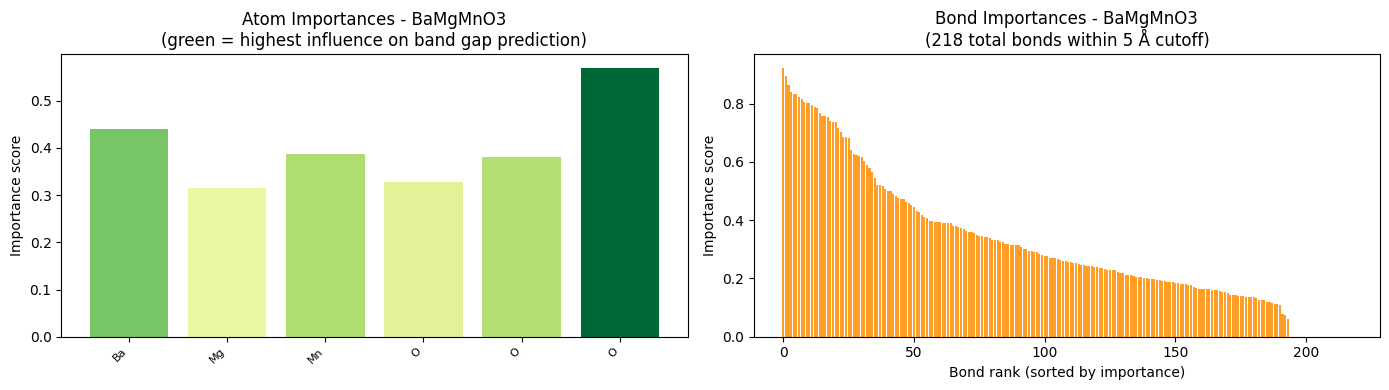


Interpretation: BaMgMnO3
  Most influential element : Ba  (mean importance 0.4404)
  Most influential bond    : O–Ba

  Node importance - Ba sites dominate this prediction. The model is
  weighting that element's chemical features (electronegativity, atomic
  radius, ionisation energy) most heavily when estimating the gap between
  the valence and conduction bands.

  Edge importance - high-scoring bonds represent the inter-atomic couplings
  where orbital overlap and crystal-field effects most strongly govern the
  electronic structure. Shorter, more directional bonds tend to score higher.


In [10]:
best_name = min(gnn_results, key=lambda k: gnn_results[k]['test']['mae_bandgap'])
best_model = gnn_results[best_name]['model'].to('cpu').eval()
print(f'Best model: {best_name}')

sample = test_g[0]
print(f'Chosen Formula to Explain: {sample.formula}  (true band gap = {sample.y[0,0]:.3f} eV)')

try:
    from torch_geometric.explain import Explainer, GNNExplainer
    explainer = Explainer(
        model=best_model,
        algorithm=GNNExplainer(epochs=150),
        explanation_type='model',
        node_mask_type='attributes',
        edge_mask_type='object',
        model_config=dict(mode='regression', task_level='graph', return_type='raw'),
    )
    expl = explainer(
        x=sample.x,
        edge_index=sample.edge_index,
        batch=torch.zeros(sample.num_nodes, dtype=torch.long),
    )
    node_imp = expl.node_mask.mean(dim=-1).detach().numpy()
    edge_imp = expl.edge_mask.detach().numpy()
    print('Using PyG 2.x Explainer API')
except Exception as e:
    print(f'PyG 2.x API unavailable ({e}), falling back to legacy GNNExplainer')
    from torch_geometric.nn import GNNExplainer as LegacyExplainer
    exp = LegacyExplainer(best_model, epochs=150, return_type='raw')
    node_feat_mask, edge_mask = exp.explain_graph(sample.x, sample.edge_index)
    node_imp = node_feat_mask.mean(dim=-1).detach().numpy()
    edge_imp = edge_mask.detach().numpy()

struct_row = df[df['material_id'] == sample.material_id]
if len(struct_row) == 0:
    struct_row = df[df['formula'] == sample.formula]
struct     = struct_row.iloc[0]['structure']
elem_names = [site.specie.symbol for site in struct]

node_df = pd.DataFrame({
    'Atom Index': range(len(node_imp)),
    'Element':    elem_names[:len(node_imp)],
    'Importance': node_imp.round(4),
}).sort_values('Importance', ascending=False)

print(f'\nPer-atom importance ranking ({sample.formula})')
print(node_df.to_string(index=False))

elem_agg = (
    node_df.groupby('Element')['Importance']
    .agg(Mean='mean', Max='max', Sites='count')
    .sort_values('Mean', ascending=False)
    .round(4)
)
print(f'\nElement-level summary')
print(elem_agg.to_string())

src_idx = sample.edge_index[0].numpy()
dst_idx = sample.edge_index[1].numpy()
n = len(elem_names)
bond_labels = [
    f'{elem_names[min(i, n-1)]}–{elem_names[min(j, n-1)]}'
    for i, j in zip(src_idx, dst_idx)
]
edge_df = pd.DataFrame({
    'Bond':       bond_labels,
    'Src':        src_idx,
    'Dst':        dst_idx,
    'Importance': edge_imp.round(4),
}).sort_values('Importance', ascending=False).head(10)

print(f'\nTop 10 most influential bonds')
print(edge_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

node_colors = plt.cm.RdYlGn(node_imp / (node_imp.max() + 1e-9))
axes[0].bar(range(len(node_imp)), node_imp, color=node_colors)
axes[0].set_xticks(range(len(node_imp)))
axes[0].set_xticklabels(elem_names[:len(node_imp)], rotation=45, ha='right', fontsize=8)
axes[0].set(ylabel='Importance score',
            title=f'Atom Importances - {sample.formula}\n(green = highest influence on band gap prediction)')

sorted_edge = np.sort(edge_imp)[::-1]
axes[1].bar(range(len(sorted_edge)), sorted_edge, color='darkorange', alpha=0.85)
axes[1].set(xlabel='Bond rank (sorted by importance)', ylabel='Importance score',
            title=f'Bond Importances - {sample.formula}\n({len(edge_imp)} total bonds within 5 Å cutoff)')

plt.tight_layout()
plt.savefig('data/gnnexplainer.png', dpi=120, bbox_inches='tight')
plt.show()

top_elem = elem_agg.index[0]
top_mean = elem_agg['Mean'].iloc[0]
top_bond = edge_df.iloc[0]['Bond'] if len(edge_df) > 0 else 'N/A'

print(f'\nInterpretation: {sample.formula}')
print(f'  Most influential element : {top_elem}  (mean importance {top_mean:.4f})')
print(f'  Most influential bond    : {top_bond}')
print()
print(f'  Node importance - {top_elem} sites dominate this prediction. The model is')
print(f'  weighting that element\'s chemical features (electronegativity, atomic')
print(f'  radius, ionisation energy) most heavily when estimating the gap between')
print(f'  the valence and conduction bands.')
print()
print(f'  Edge importance - high-scoring bonds represent the inter-atomic couplings')
print(f'  where orbital overlap and crystal-field effects most strongly govern the')
print(f'  electronic structure. Shorter, more directional bonds tend to score higher.')

## Step 7: Climate Integration (NASA POWER)

In [11]:
import requests

NASA_POWER_URL = 'https://power.larc.nasa.gov/api/temporal/climatology/point'

def fetch_climate(lat: float, lon: float) -> dict:
    try:
        resp = requests.get(
            NASA_POWER_URL,
            params={'parameters': 'ALLSKY_SFC_SW_DWN,T2M', 'community': 'RE',
                    'longitude': lon, 'latitude': lat, 'format': 'JSON'},
            timeout=20,
        )
        resp.raise_for_status()
        props = resp.json()['properties']['parameter']
        irr  = np.mean(list(props['ALLSKY_SFC_SW_DWN'].values()))
        temp = np.mean(list(props['T2M'].values()))
        return {'irradiance_kwh_m2_day': round(float(irr), 3), 'mean_temp_C': round(float(temp), 2)}
    except Exception as exc:
        print(f'  NASA POWER failed ({exc}) — using regional placeholder')
        return {'irradiance_kwh_m2_day': 4.5, 'mean_temp_C': 20.0}

print(f'Fetching climate data for {CITY} ({CITY_LAT}°N, {CITY_LON}°E) ...')
city_climate = fetch_climate(CITY_LAT, CITY_LON)
irr_day = city_climate['irradiance_kwh_m2_day']

print(f'  Irradiance : {irr_day} kWh/m²/day')
print(f'  Mean temp  : {city_climate["mean_temp_C"]} °C')
print(f'  Annual     : {irr_day * 365:.0f} kWh/m²/year')

Fetching climate data for Baton Rouge, LA (30.45°N, -91.15°E) ...
  Irradiance : 4.661 kWh/m²/day
  Mean temp  : 19.74 °C
  Annual     : 1701 kWh/m²/year


## Step 8: Solar Yield Ranking vs Silicon

In [14]:
# Spectral match peaks at the theoretical optimum (1.34 eV).
# Materials with FE > 0 are thermodynamically unstable and yield = 0.
OPTIMAL_BG  = 1.34    # eV — S-Q theoretical peak
SI_BAND_GAP = 1.12    # eV
SI_FE       = -0.005  # eV/atom

def yield_proxy(band_gap: float, fe: float, irr_day: float) -> float:
    if fe > 0 or band_gap <= 0:
        return 0.0
    spectral = max(0.0, 1.0 - abs(band_gap - OPTIMAL_BG) / OPTIMAL_BG)
    return round(spectral * irr_day * 365, 2)

#silicon reference
si_yield = yield_proxy(SI_BAND_GAP, SI_FE, irr_day)
print(f'Silicon baseline ({CITY}): {si_yield:.1f} kWh/m²/year')

best_model = best_model.to(DEVICE).eval()

meta, preds_list = [], []
with torch.no_grad():
    for g in test_g:
        g2 = g.clone()
        g2.batch = torch.zeros(g.num_nodes, dtype=torch.long, device=DEVICE)
        g2 = g2.to(DEVICE)
        p = best_model(g2)[0].cpu().numpy()
        preds_list.append(p)
        meta.append({'material_id': g.material_id, 'formula': g.formula})

pred_arr = np.array(preds_list)
results_df = pd.DataFrame(meta)
results_df['pred_band_gap']   = pred_arr[:, 0].round(4)
results_df['pred_fe']         = pred_arr[:, 1].round(4)
results_df['yield_kwh_m2_yr'] = results_df.apply(
    lambda r: yield_proxy(r['pred_band_gap'], r['pred_fe'], irr_day), axis=1
)
results_df['vs_silicon_raw'] = results_df['yield_kwh_m2_yr'] - si_yield

top10 = (
    results_df[results_df['pred_fe'] < 0]
    .nlargest(10, 'yield_kwh_m2_yr')
    .copy()
)

si_row = pd.DataFrame([{
    'material_id':     'Si',
    'formula':         'Si (baseline)',
    'pred_band_gap':   SI_BAND_GAP,
    'pred_fe':         SI_FE,
    'yield_kwh_m2_yr': si_yield,
    'vs_silicon_raw':  0.0,
}])
display_df = pd.concat([si_row, top10], ignore_index=True)

display_df['vs_silicon'] = display_df['vs_silicon_raw'].apply(
    lambda v: f'+{v:.2f}' if v >= 0 else f'{v:.2f}'
)

display_df = display_df.rename(columns={
    'formula':         'Material',
    'pred_band_gap':   'Band Gap (eV)',
    'pred_fe':         'Form. Energy (eV/atom)',
    'yield_kwh_m2_yr': f'Yield in {CITY} (kWh/m²/yr)',
    'vs_silicon':      'vs Silicon',
})[['Material', 'Band Gap (eV)', 'Form. Energy (eV/atom)',
    f'Yield - {CITY} (kWh/m²/yr)', 'vs Silicon']]

print(f'\nTop 10 candidates vs silicon in {CITY} (irr = {irr_day} kWh/m²/day)')
display_df

Silicon baseline (Baton Rouge, LA): 1422.0 kWh/m²/year


KeyError: "['Yield - Baton Rouge, LA (kWh/m²/yr)'] not in index"

In [ ]:
print('GNN model comparison')
print(gnn_cmp.to_string(index=False))
print('\nBaseline comparison')
print(baseline_metrics.to_string(index=False))

best_bg_gnn = gnn_cmp['MAE Band Gap (eV)'].min()
best_bg_bl  = baseline_metrics.loc[baseline_metrics['target'] == 'band_gap', 'test_mae'].min()

#results much better in colab, data importing to machines may skew data
print(f'\nBand gap MAE - best GNN: {best_bg_gnn:.4f} eV  /  best baseline: {best_bg_bl:.4f} eV')
print(f'GNN improvement over baseline: {best_bg_bl - best_bg_gnn:.4f} eV')

── GNN model comparison ──
Model  Saved Epoch  MAE Band Gap (eV)  MAE Formation (eV/atom)  Physics Loss (test)
  GCN           71             0.5400                   0.1716              0.57842
  GAT           73             0.4977                   0.1442              0.48870
  GIN           36             0.5963                   0.2692              0.78933

── Baseline comparison ──
            model           target         cv_mae  test_mae  test_rmse  test_r2
    Random Forest         band_gap — (pretrained)    0.4415     0.5840   0.5325
    Random Forest formation_energy — (pretrained)    0.1208     0.2136   0.9430
Gradient Boosting         band_gap — (pretrained)    0.5550     0.6815   0.3634
Gradient Boosting formation_energy — (pretrained)    0.1979     0.2789   0.9029

Band gap MAE — best GNN: 0.4977 eV  |  best baseline: 0.4415 eV
GNN improvement over baseline: -0.0562 eV
